# Example 1 — Gill response (resting basic state)

Manuscript Sect. 4.1. A **resting, isothermal** atmosphere forced by a steady equatorial Gaussian heating produces the classic Gill pattern: a Kelvin wave to the east and a pair of Rossby gyres to the west, with an analytic east/west e-folding ratio of ~3.

## 1. Set up the model (T42 L20, Isca/GFDL core)

In [1]:
# --- locate the LBM_isca package and the shared input data -------------------
import os, sys, types
import numpy as np

root = os.path.abspath("")
while root != os.path.dirname(root):
    if os.path.isdir(os.path.join(root, "lbm_isca")):
        break
    root = os.path.dirname(root)
sys.path.insert(0, root)
DATA = os.path.join(os.path.dirname(root), "LBM_python_GPU")  # bs.*.bin / frc.*.bin

from lbm_isca import Config, LBM, Spectral, VerticalGrid, asnumpy, gpu_available
from lbm_isca.forcing import SteadyForcing, MJOForcing
from lbm_isca.basicstate import load_basic_state

DEVICE = "gpu" if gpu_available() else "cpu"
sp = Spectral(device=DEVICE)
vg = VerticalGrid(device=DEVICE)
lon, lat, sig = asnumpy(sp.lon_deg), asnumpy(sp.lat_deg), asnumpy(vg.sig)
print(f"LBM_isca  T{sp.nmax}  {sp.nlon}x{sp.nlat}  L{vg.kmax}  backend={DEVICE}")

LBM_isca  T42  128x64  L20  backend=gpu


## 2. Basic state

The basic state is the simplest possible: **no flow, uniform 250 K, 1000 hPa surface.** There is nothing for the perturbation to advect, so the response is purely the heating-driven Gill circulation.

> **This is the only block that changes between the three examples — swap it to run a different case.**

In [3]:
# BASIC STATE — resting isothermal atmosphere
shape = (sp.nlat, sp.nlon, vg.kmax)
bs = types.SimpleNamespace(
u=np.zeros(shape), v=np.zeros(shape),
t=np.full(shape, 250.0), q=np.zeros(shape),
ps=np.full((sp.nlat, sp.nlon), 1000.0))

## 3. Forcing

Steady equatorial Gaussian heating centred on the date line (1 K day$^{-1}$, half-widths 20° lon / 10° lat, mid-tropospheric half-sine vertical profile).

In [4]:
frc = SteadyForcing.zeros(sp.nlat, sp.nlon, vg.kmax)
dl = (lon[None, :] - 180.0 + 180.0) % 360.0 - 180.0
hxy = np.exp(-(dl / 20.0) ** 2 - (lat[:, None] / 10.0) ** 2)
vz = np.sin(np.pi * (1.0 - sig)) * (sig > 0.1)
frc.t = hxy[:, :, None] * vz[None, None, :] * (1.0 / 86400.0)  # K/s

## 4. Integrate

In [5]:
model = LBM(bs, sp, vg, Config(ndays=6.0))
model.run(steady_forcing=frc, verbose=True)

  backend: gpu
  day   3.33  |u|max   0.842  |T|max  0.274  |ps|max  0.3477   [ 18.4s]
  done: 432 steps, 32.9s


## 5. Look at the response

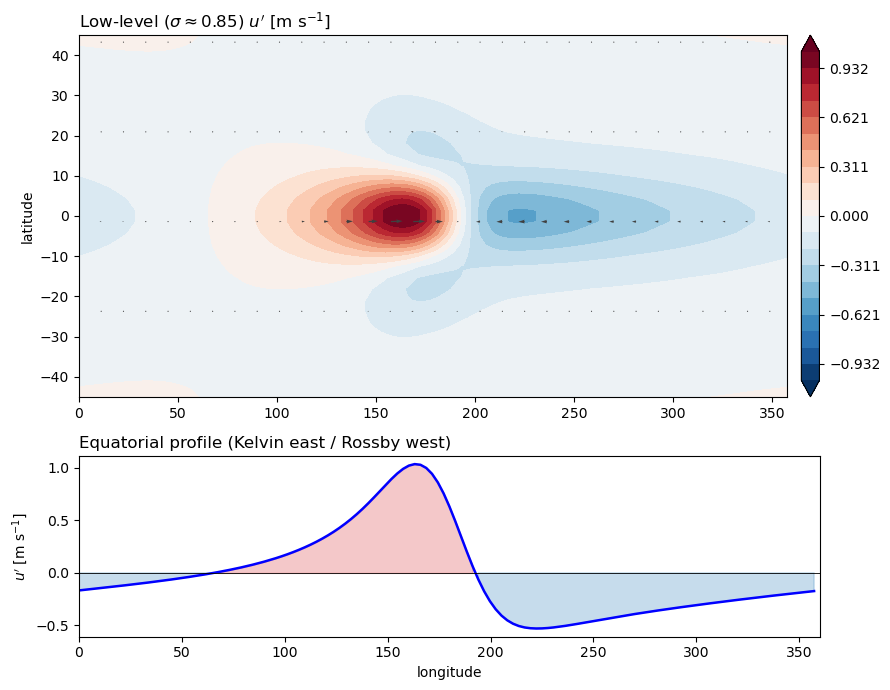

In [6]:
# --- quick look: low-level (sigma ~ 0.85) zonal-wind response ----------------
import matplotlib.pyplot as plt

k = int(np.argmin(np.abs(sig - 0.85)))
u = asnumpy(model.ga.u[:, :, k])
v = asnumpy(model.ga.v[:, :, k])

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(9, 7),
                               gridspec_kw={"height_ratios": [2, 1]})
vmax = np.abs(u).max() or 1.0
cf = ax0.contourf(lon, lat, u, levels=np.linspace(-vmax, vmax, 21),
                  cmap="RdBu_r", extend="both")
ax0.quiver(lon[::4], lat[::8], u[::8, ::4], v[::8, ::4], scale=60,
           width=0.0018, color="0.25")
ax0.set_ylim(-45, 45); ax0.set_ylabel("latitude")
ax0.set_title(r"Low-level ($\sigma\approx0.85$) $u'$ [m s$^{-1}$]", loc="left")
fig.colorbar(cf, ax=ax0, pad=0.02, fraction=0.025)

eq = int(np.argmin(np.abs(lat)))
ax1.plot(lon, u[eq], "b-", lw=1.8); ax1.axhline(0, color="k", lw=0.6)
ax1.fill_between(lon, 0, u[eq], where=u[eq] > 0, color="tab:red", alpha=0.25)
ax1.fill_between(lon, 0, u[eq], where=u[eq] < 0, color="tab:blue", alpha=0.25)
ax1.set_xlim(0, 360); ax1.set_xlabel("longitude")
ax1.set_ylabel(r"$u'$ [m s$^{-1}$]")
ax1.set_title("Equatorial profile (Kelvin east / Rossby west)", loc="left")
fig.tight_layout(); plt.show()

## 6. (optional) Save gridded output

In [ ]:
# --- (optional) write GrADS + netCDF output ----------------------------------
from lbm_isca.output import GradsWriter  # NetCDFWriter also available
os.makedirs(os.path.join(root, "out"), exist_ok=True)
# Re-run with a writer attached if you want the full gridded history on disk:
#   w = GradsWriter(os.path.join(root, "out", "gill.grd"), sp, vg)
#   model.run(steady_forcing=frc, writer=w)
print("final-state grid fields available as model.ga.u / .v / .t / .psi ...")